# DSC8307 Data Mining, Modeling and Analytics

**Student:** Joshua Micaiah Opaman  
**Programme:** Master of Science in Data Science and Analytics  
**Course:** DSC8307  


# Project 2: Concrete Compressive Strength

## 1. Problem formulation

The target is concrete compressive strength in MPa. This is supervised regression using seven mixture components and curing age. The objective is predictive accuracy on unseen observations, not proof that changing one ingredient will cause a particular strength response. The analysis compares a linear model with flexible non-linear ensembles, uses a mean-prediction baseline, cross-validation, held-out testing and residual diagnostics.

In [1]:
import warnings,sys
warnings.filterwarnings('ignore')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.model_selection import train_test_split,KFold,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor,RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.inspection import permutation_importance,PartialDependenceDisplay
RANDOM_STATE=42
print('Python',sys.version.split()[0], '| pandas',pd.__version__)

Python 3.13.5 | pandas 2.2.3


## 2. Data loading, quality and exploratory analysis

In [2]:
df=pd.read_csv('Concrete_Data.csv')
df.columns=[c.strip() for c in df.columns]
print('Shape:',df.shape,'| duplicates:',df.duplicated().sum())
display(df.head())
display(pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()}))
display(df.describe().T.round(3))

Shape: (1030, 9) | duplicates: 25


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,dtype,missing,unique
Cement (kg in a m^3 mixture),float64,0,280
Blast Furnace Slag (kg in a m^3 mixture),float64,0,187
Fly Ash (kg in a m^3 mixture),float64,0,163
Water (kg in a m^3 mixture),float64,0,205
Superplasticizer (kg in a m^3 mixture),float64,0,155
Coarse Aggregate (kg in a m^3 mixture),float64,0,284
Fine Aggregate (kg in a m^3 mixture),float64,0,304
Age (day),int64,0,14
"Concrete compressive strength (MPa, megapascals)",float64,0,938


,count,mean,std,min,25%,50%,75%,max
Cement (kg in a m^3 mixture),1030.0,281.166,104.507,102.000,192.375,272.900,350.000,540.000
Blast Furnace Slag (kg in a m^3 mixture),1030.0,73.895,86.279,0.000,0.000,22.000,142.950,359.400
Fly Ash (kg in a m^3 mixture),1030.0,54.187,63.996,0.000,0.000,0.000,118.270,200.100
Water (kg in a m^3 mixture),1030.0,181.566,21.356,121.750,164.900,185.000,192.000,247.000
Superplasticizer (kg in a m^3 mixture),1030.0,6.203,5.973,0.000,0.000,6.350,10.160,32.200
Coarse Aggregate (kg in a m^3 mixture),1030.0,972.919,77.754,801.000,932.000,968.000,1029.400,1145.000
Fine Aggregate (kg in a m^3 mixture),1030.0,773.579,80.175,594.000,730.950,779.510,824.000,992.600
Age (day),1030.0,45.662,63.170,1.000,7.000,28.000,56.000,365.000
"Concrete compressive strength (MPa, megapascals)",1030.0,35.818,16.706,2.332,23.707,34.443,46.136,82.599


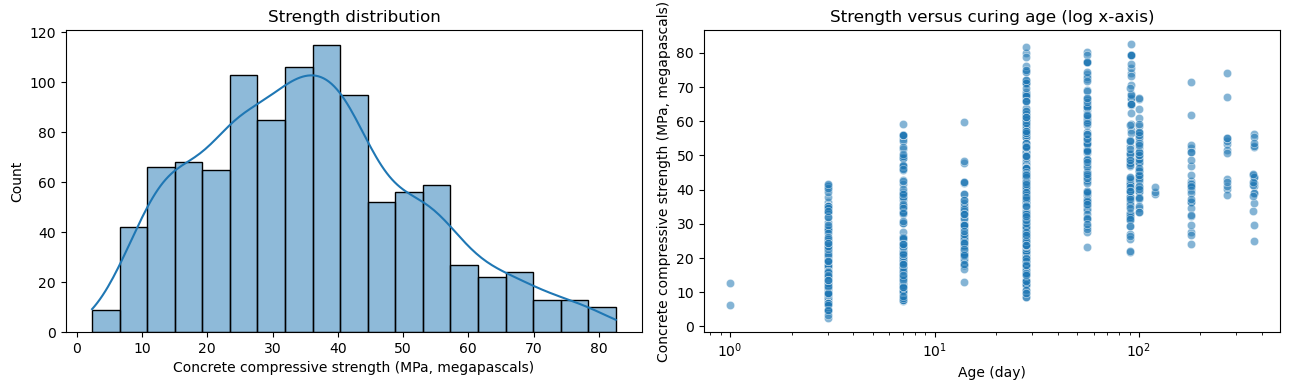

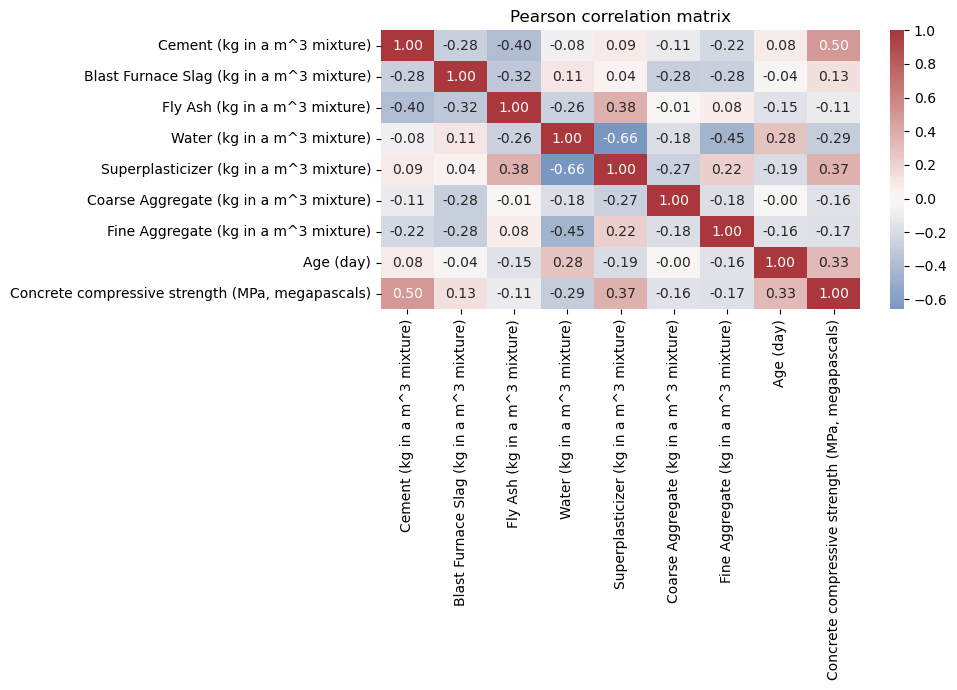

In [3]:
target=df.columns[-1]
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df[target],kde=True,ax=ax[0]);ax[0].set_title('Strength distribution')
sns.scatterplot(data=df,x='Age (day)',y=target,alpha=.55,ax=ax[1]);ax[1].set_xscale('log');ax[1].set_title('Strength versus curing age (log x-axis)')
plt.tight_layout();plt.show()
plt.figure(figsize=(10,7));sns.heatmap(df.corr(numeric_only=True),cmap='vlag',center=0,annot=True,fmt='.2f');plt.title('Pearson correlation matrix');plt.tight_layout();plt.show()

### Preparation justification
All fields are quantitative. Missingness and duplicates are reported rather than silently altered. Exact duplicate experimental records may represent repeated measurements, so they are retained in the primary analysis; a grouped/duplicate sensitivity check is added later. Median imputation is included inside pipelines for reproducibility even if no values are missing. Ridge regression standardizes inputs. Tree models do not require scaling. A fixed 20% test set is held out, while five-fold shuffled cross-validation on training data assesses stability.

In [4]:
X=df.iloc[:,:-1]; y=df.iloc[:,-1]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE)
cv=KFold(5,shuffle=True,random_state=RANDOM_STATE)
models={
 'Mean baseline':Pipeline([('imp',SimpleImputer(strategy='median')),('model',DummyRegressor(strategy='mean'))]),
 'Ridge linear':Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',Ridge(alpha=10.0))]),
 'Random forest':Pipeline([('imp',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=600,min_samples_leaf=2,max_features=.9,n_jobs=-1,random_state=RANDOM_STATE))]),
 'Histogram gradient boosting':Pipeline([('imp',SimpleImputer(strategy='median')),('model',HistGradientBoostingRegressor(max_iter=350,learning_rate=.06,max_leaf_nodes=31,l2_regularization=1.0,random_state=RANDOM_STATE))])}
scoring={'MAE':'neg_mean_absolute_error','RMSE':'neg_root_mean_squared_error','R2':'r2'}
rows=[]
for name,m in models.items():
 r=cross_validate(m,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
 rows.append({'model':name,'MAE_mean':-r['test_MAE'].mean(),'MAE_sd':r['test_MAE'].std(),'RMSE_mean':-r['test_RMSE'].mean(),'RMSE_sd':r['test_RMSE'].std(),'R2_mean':r['test_R2'].mean(),'R2_sd':r['test_R2'].std()})
cvres=pd.DataFrame(rows).sort_values('RMSE_mean');display(cvres.round(4))

,model,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd
3,Histogram gradient boosting,3.1471,0.2880,4.7996,0.4025,0.9177,0.0135
2,Random forest,3.8558,0.2285,5.4184,0.4550,0.8949,0.0190
1,Ridge linear,8.4896,0.3969,10.6543,0.4488,0.5952,0.0452
0,Mean baseline,13.5828,0.5552,16.8853,0.4567,-0.0120,0.0076


## 3. Held-out comparison of linear and non-linear approaches

In [5]:
fitted={};rows=[]
for name,m in models.items():
 m.fit(X_train,y_train);fitted[name]=m;p=m.predict(X_test)
 rows.append({'model':name,'MAE':mean_absolute_error(y_test,p),'RMSE':mean_squared_error(y_test,p)**.5,'R2':r2_score(y_test,p)})
testres=pd.DataFrame(rows).sort_values('RMSE');display(testres.round(4))
best_name=testres.iloc[0].model;best=fitted[best_name];pred=best.predict(X_test)
print('Selected model:',best_name)

  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.

,model,MAE,RMSE,R2
3,Histogram gradient boosting,2.8668,4.4288,0.9239
2,Random forest,3.9565,5.5946,0.8785
1,Ridge linear,7.8089,9.8121,0.6264
0,Mean baseline,13.0524,16.0537,-0.0002


Selected model: Histogram gradient boosting


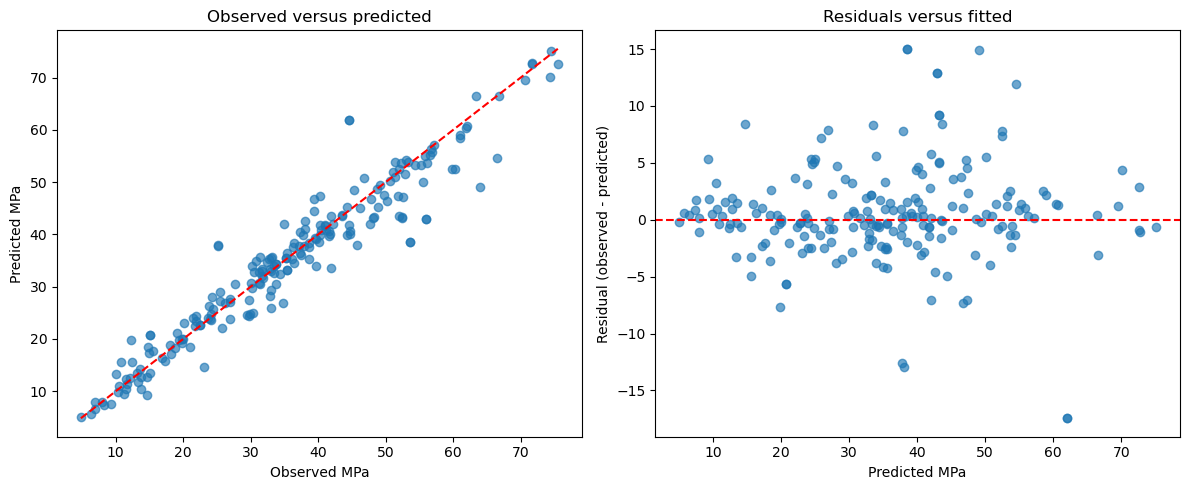

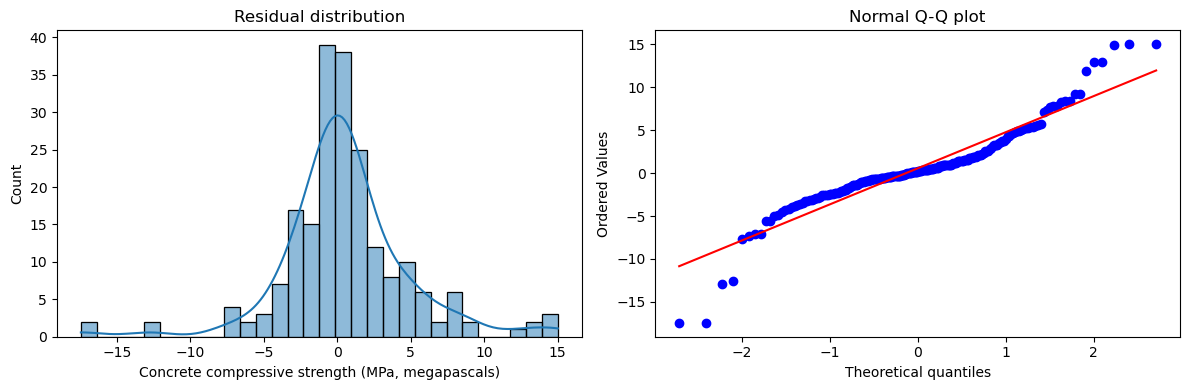

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,5))
ax[0].scatter(y_test,pred,alpha=.65);lims=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())];ax[0].plot(lims,lims,'r--');ax[0].set(xlabel='Observed MPa',ylabel='Predicted MPa',title='Observed versus predicted')
res=y_test-pred;ax[1].scatter(pred,res,alpha=.65);ax[1].axhline(0,color='r',ls='--');ax[1].set(xlabel='Predicted MPa',ylabel='Residual (observed - predicted)',title='Residuals versus fitted')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4));sns.histplot(res,kde=True,ax=ax[0]);ax[0].set_title('Residual distribution');import scipy.stats as st
st.probplot(res,dist='norm',plot=ax[1]);ax[1].set_title('Normal Q-Q plot');plt.tight_layout();plt.show()

## 4. Where predictions are weakest

In [7]:
diag=X_test.copy();diag['actual']=y_test;diag['predicted']=pred;diag['residual']=res;diag['abs_error']=abs(res)
diag['strength_quartile']=pd.qcut(diag.actual,4,labels=['Q1 lowest','Q2','Q3','Q4 highest'])
diag['age_band']=pd.cut(diag['Age (day)'],bins=[0,7,28,90,366],labels=['1-7','8-28','29-90','91-365'],include_lowest=True)
by_strength=diag.groupby('strength_quartile',observed=True).agg(n=('abs_error','size'),MAE=('abs_error','mean'),bias=('residual','mean'),RMSE=('residual',lambda z:np.sqrt(np.mean(z**2))))
by_age=diag.groupby('age_band',observed=True).agg(n=('abs_error','size'),MAE=('abs_error','mean'),bias=('residual','mean'),RMSE=('residual',lambda z:np.sqrt(np.mean(z**2))))
display(by_strength.round(3));display(by_age.round(3))
print('Ten weakest predictions:');display(diag.sort_values('abs_error',ascending=False).head(10).round(2))

,n,MAE,bias,RMSE
strength_quartile,,,,
Q1 lowest,52,1.834,-0.427,2.647
Q2,51,2.795,-0.375,3.977
Q3,51,2.848,-0.489,4.611
Q4 highest,52,3.988,3.491,5.859


,n,MAE,bias,RMSE
age_band,,,,
1-7,56,2.661,0.699,3.973
8-28,91,3.564,0.360,5.440
29-90,29,1.851,0.732,2.506
91-365,30,2.118,0.737,3.062


Ten weakest predictions:


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),actual,predicted,residual,abs_error,strength_quartile,age_band
971,312.70,144.7,0.00,127.3,8.00,999.7,822.20,28,44.52,61.97,-17.44,17.44,Q3,8-28
908,313.00,145.0,0.00,127.0,8.00,1000.0,822.00,28,44.52,61.95,-17.43,17.43,Q3,8-28
1001,297.80,137.2,106.90,201.3,6.00,878.4,655.30,28,53.52,38.50,15.02,15.02,Q4 highest,8-28
844,298.00,137.0,107.00,201.0,6.00,878.0,655.00,28,53.52,38.50,15.02,15.02,Q4 highest,8-28
382,505.00,0.0,60.00,195.0,0.00,1030.0,630.00,28,64.02,49.07,14.95,14.95,Q4 highest,8-28
109,362.60,189.0,0.00,164.9,11.60,944.7,755.80,7,55.90,42.96,12.94,12.94,Q4 highest,1-7
106,362.60,189.0,0.00,164.9,11.60,944.7,755.80,7,55.90,42.96,12.94,12.94,Q4 highest,1-7
919,313.00,0.0,0.00,178.0,8.00,1000.0,822.00,28,25.10,38.03,-12.93,12.93,Q2,8-28
982,312.70,0.0,0.00,178.1,8.00,999.7,822.20,28,25.10,37.69,-12.58,12.58,Q2,8-28
333,246.83,0.0,125.08,143.3,11.99,1086.8,800.89,100,66.42,54.54,11.89,11.89,Q4 highest,91-365


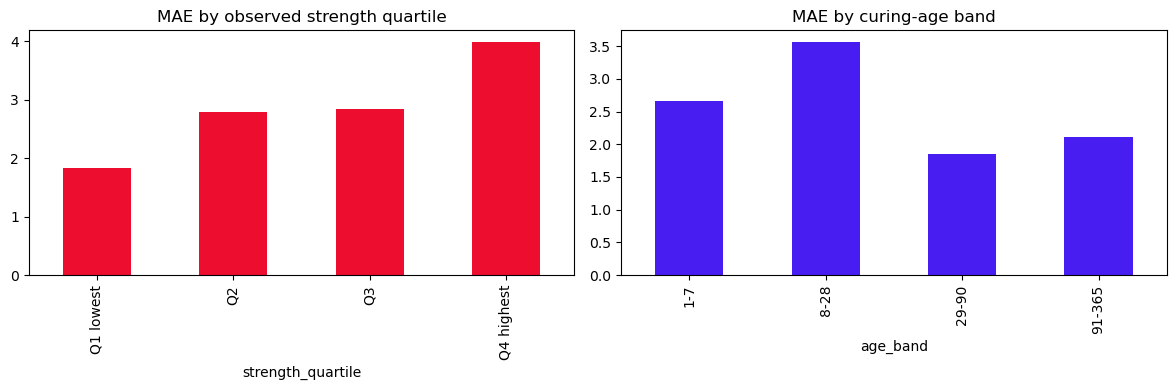

In [13]:
fig,ax=plt.subplots(1,2,figsize=(12,4));by_strength.MAE.plot(kind='bar',ax=ax[0],color="#ed0e2f",title='MAE by observed strength quartile');by_age.MAE.plot(kind='bar',ax=ax[1],color="#481df2",title='MAE by curing-age band');plt.tight_layout();plt.show()

## 5. Interpretation and sensitivity analysis

,feature,importance_mean,importance_sd
7,Age (day),10.6999,0.4598
0,Cement (kg in a m^3 mixture),7.8100,0.4965
3,Water (kg in a m^3 mixture),4.2994,0.3011
1,Blast Furnace Slag (kg in a m^3 mixture),3.5106,0.3190
4,Superplasticizer (kg in a m^3 mixture),2.3488,0.2147
6,Fine Aggregate (kg in a m^3 mixture),1.3092,0.2044
5,Coarse Aggregate (kg in a m^3 mixture),0.5960,0.0761
2,Fly Ash (kg in a m^3 mixture),0.1581,0.0473


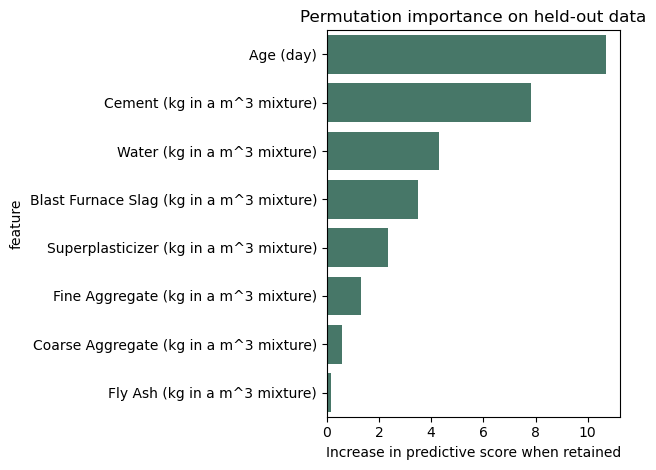

In [9]:
perm=permutation_importance(best,X_test,y_test,n_repeats=20,random_state=RANDOM_STATE,scoring='neg_root_mean_squared_error',n_jobs=-1)
imp=pd.DataFrame({'feature':X.columns,'importance_mean':perm.importances_mean,'importance_sd':perm.importances_std}).sort_values('importance_mean',ascending=False)
display(imp.round(4))
sns.barplot(data=imp,x='importance_mean',y='feature',color='#3f7f6b');plt.xlabel('Increase in predictive score when retained');plt.title('Permutation importance on held-out data');plt.tight_layout();plt.show()

In [11]:
# Duplicate sensitivity: remove exact duplicate rows, retrain same selected model and compare
dedup=df.drop_duplicates();Xd=dedup.iloc[:,:-1];yd=dedup.iloc[:,-1]
Xd_tr,Xd_te,yd_tr,yd_te=train_test_split(Xd,yd,test_size=.20,random_state=RANDOM_STATE)
import copy
model_d=copy.deepcopy(models[best_name]).fit(Xd_tr,yd_tr);pd_=model_d.predict(Xd_te)
print({'original_n':len(df),'deduplicated_n':len(dedup),'deduplicated_MAE':round(mean_absolute_error(yd_te,pd_),3),'deduplicated_RMSE':round(mean_squared_error(yd_te,pd_)**.5,3),'deduplicated_R2':round(r2_score(yd_te,pd_),3)})

{'original_n': 1030, 'deduplicated_n': 1005, 'deduplicated_MAE': 2.834, 'deduplicated_RMSE': 4.401, 'deduplicated_R2': 0.935}


## 6. Does predictive association imply a real-world intervention effect?

**No.** A predictive association between cement content and strength does not prove what would happen if cement were deliberately changed. The dataset is observational/experimental-record data in which ingredients are jointly chosen. Cement is correlated with water, slag, fly ash, aggregate proportions, superplasticizer, curing age and mix-design decisions. Changing cement while holding everything else mathematically fixed may describe combinations that are physically infeasible or outside the observed support. Unmeasured factors such as curing temperature, specimen geometry, batching quality and testing conditions may also confound the relationship.

Permutation importance answers a predictive question: how much test performance deteriorates when a feature's information is disrupted. It is not a causal effect size. To estimate an intervention effect, one needs a designed experiment or credible causal design with pre-specified feasible mixtures, random assignment of cement levels, controlled water-to-binder ratio and curing conditions, sufficient replication, and analysis of interactions. Safety-critical mix changes must be validated through laboratory testing and engineering standards, not made from this model alone.

## 7. Conclusions and recommendations

- The mean model provides a necessary baseline. A useful model must reduce MAE/RMSE and increase R2 materially beyond it.
- Ridge represents the additive linear approach. The non-linear ensembles can capture diminishing returns, interactions and age-dependent relationships. Selection is based on cross-validation plus held-out performance, not training fit.
- Residual summaries identify the strength and age regions where predictions are weakest. These regions should receive additional data collection and cautious prediction intervals.
- Duplicate sensitivity assesses whether exact repeated rows materially influence results.

**Recommendation:** use the selected non-linear model for provisional prediction within the range of the observed data, accompanied by the reported error metrics and residual limitations. Do not extrapolate to novel mixtures without laboratory validation. For deployment, collect an external batch from a different production period or laboratory and confirm MAE, RMSE, calibration of residual spread, and worst-case errors before operational use.